# Abstract
We have a Facebook app-install campaign that, according to the campaign data, is underperforming in the last weeks (negative profit for ad-installs).

In this document we will analyse the reason for this decreasing performance: higher acquisition costs & lower conversion rate. As well as why the outlook is not as grim as it seems: there are additional downloads that probably come indirectly from the campaign, but with no attribution. If we include them in the analysis, we still se positive profits per download.

The suggested next steps are to change the campaign type to target higher value users and while this is being set up, to increase the ad spend to try to increase total profit and App Store positioning.


# Problem Statement
We have an app, and we have launched a Facebook app-install campaign to promote it during the period Oct 7 2025 to Dec 31 2025.
The campaign used one creative broad audience and only iOS Facebook app placements.
We have assigned a budget cap of 90$ per day to this campaign.

The performance of the campaign has been declining in the last weeks, we need to identify the cause and suggest next steps.

**Key assumption**: we are analyzing this right after the campaign ended (Jan 2026).

# Data
The data that is available to us is:
1. Daily downloads from `2025-08-01` to `2025-12-31`
2. Daily campaign performance data from `2025-10-07` to `2025-12-31`:
    1. Ad spend ($)
    2. CPM: cost per thousand impressions ($)
    3. CTR: click-through rate of the ad
    4. Paid downloads: number of downloads attributed to the ad
    5. CPI: cost per ad-attributed install
    6. ARPD: average revenue per ad-attributed install
    6. APPD: average profit per ad-attributed install (ARPD - CPI)


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
ads_df = pd.read_excel("../data/Ad Performance Dataset.xlsx", sheet_name="Ad Data")

# normalize column names:
col_renaming ={
    'Date': 'date',
    'Ad spend': 'ad_spend',
    'CPM': 'cpm',
    'CTR': 'ctr',
    'Paid downloads': 'paid_downloads',
    'CPI': 'cpi',
    # Average revenue per ad-attributed install.
    'ARPD (on paid downloads)': 'arpd',
    # Average profit per ad-attributed install.
    'APPD (on paid downloads)': 'appd'
}
ads_df.rename(columns=col_renaming, inplace=True)
# since the date column contains unique values, it can be used as an index.
ads_df.set_index('date', inplace=True)

downloads_df = pd.read_excel("../data/Ad Performance Dataset.xlsx", sheet_name="Downloads timeseries")

# normalize column names:
downloads_col_renaming ={
    'Date': 'date',
    'Total downloads': 'downloads',
}
downloads_df.rename(columns=downloads_col_renaming, inplace=True)
downloads_df.set_index('date', inplace=True)

# For dates that are common, we add the total downloads
ads_df['total_downloads'] = downloads_df['downloads']
ads_df['non_paid_downloads'] = ads_df['total_downloads'] - ads_df['paid_downloads']
ads_df

,ad_spend,cpm,ctr,paid_downloads,cpi,arpd,appd,total_downloads,non_paid_downloads
date,,,,,,,,,
2025-10-07,36,0.91,0.0480,1363,0.026,0.084,0.058,3154,1791
2025-10-08,90,0.90,0.0449,3123,0.029,0.083,0.054,4211,1088
2025-10-09,90,1.04,0.0460,2787,0.032,0.063,0.031,4861,2074
2025-10-10,87,1.01,0.0433,2500,0.035,0.067,0.032,4662,2162
2025-10-11,90,0.92,0.0401,2583,0.035,0.081,0.046,4408,1825
...,...,...,...,...,...,...,...,...,...
2025-12-27,90,1.21,0.0271,932,0.097,0.049,-0.048,2071,1139
2025-12-28,90,1.22,0.0290,1014,0.089,0.085,-0.004,2623,1609
2025-12-29,90,1.13,0.0274,1063,0.085,0.080,-0.005,2195,1132


# Analysis
In order to properly analyze the data, we will first visualize it. For this we will plot the daily downloads for the full available history, along with the downloads attributed to the ad.

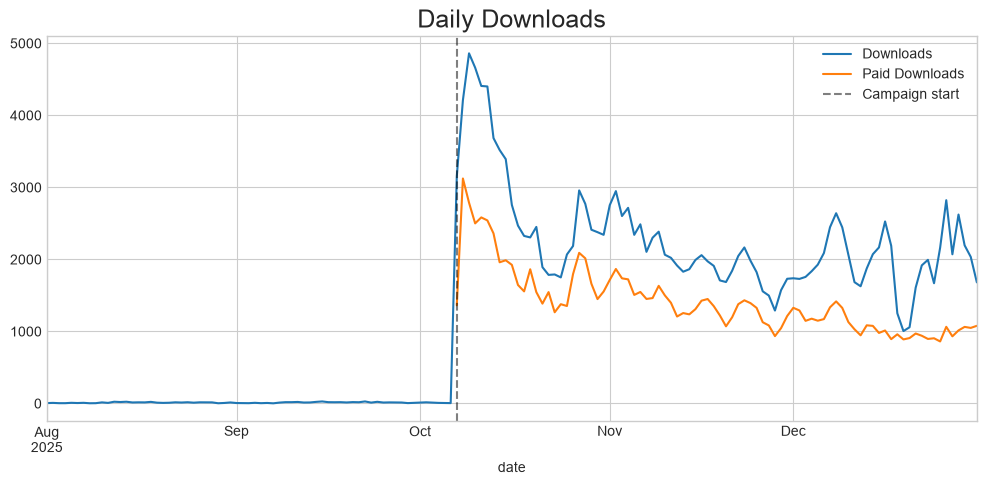

In [3]:
plt.figure(figsize=(12, 5))
downloads_df['downloads'].plot(label='Downloads')
ads_df['paid_downloads'].plot(label='Paid Downloads')
plt.axvline(ads_df.index.min(), color='k', alpha=0.5, linestyle='--', label="Campaign start")
plt.title('Daily Downloads', fontsize=18)
plt.legend()

This tells us that before the campaign started, almost no downloads existed, but not all downloads are attributed to the ad, so either there is an additional source of downloads, or the fact that we are promoting it, also increases non-paid downloads.

The total number of downloads not attributed to the campaign (while it was active) is 38% of all downloads.

## Campaign data

There is a weekly seasonal pattern in the metrics, so we can show a smoothed curve to better see the changes in trend.

We will also plot the trend (linear regression) of the series to more easily identify if a KPI is increasing/decreasing over time.

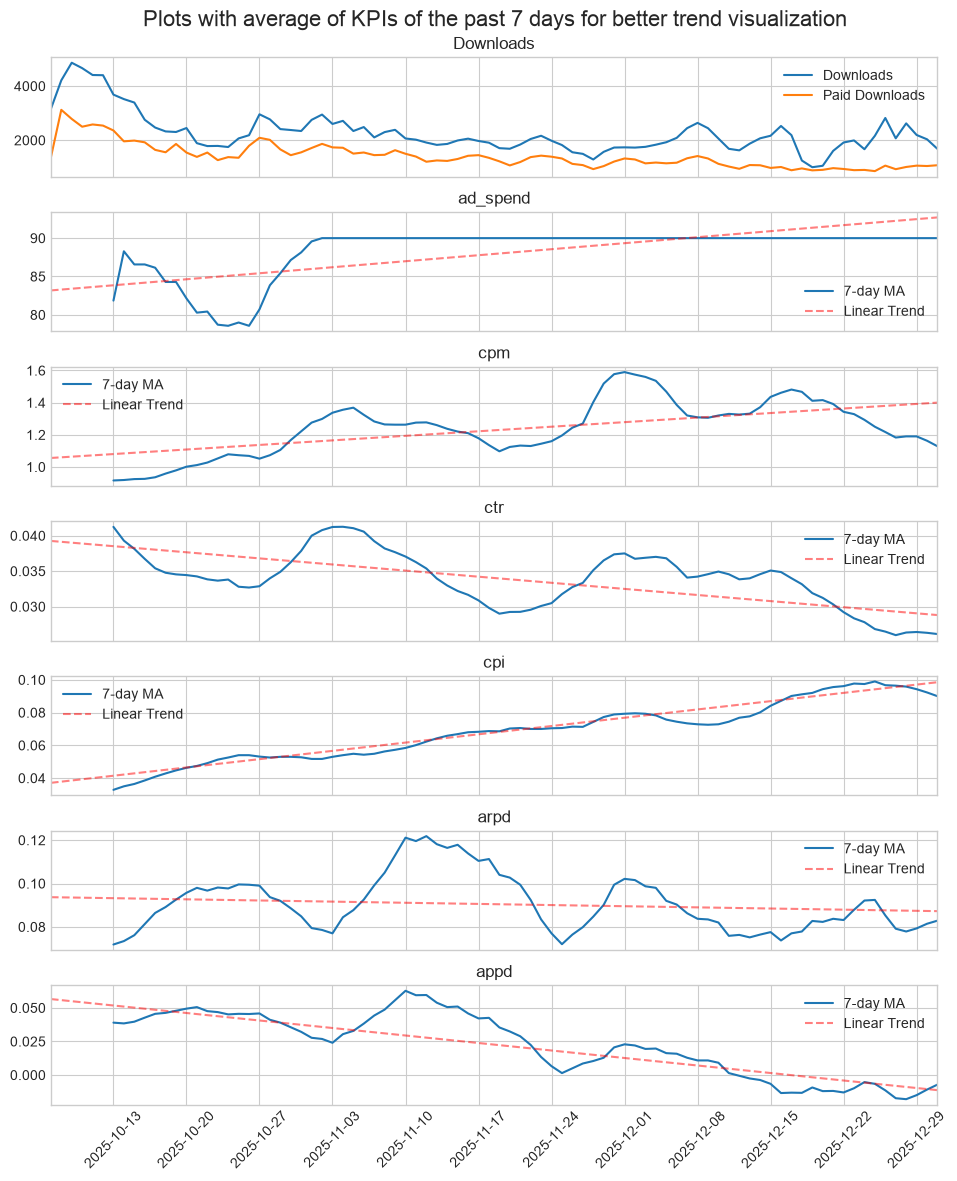

In [4]:
cols = [
    'ad_spend',
    'cpm',
    'ctr',
    # we plot this separately with the full downloads data.
    # 'paid_downloads',
    'cpi',
    'arpd',
    'appd'
]

fig, axes = plt.subplots(len(cols) + 1, 1, figsize=(10, 2*len(cols)), sharex=True)

ax = axes[0]
ads_df['total_downloads'].plot(label='Downloads', ax=ax)
ads_df['paid_downloads'].plot(label='Paid Downloads', ax=ax)
ax.set_title('Downloads')
ax.legend()

for ax, col in zip(axes[1:], cols):
    ax.plot(ads_df[col].rolling(window=7).mean().index, ads_df[col].rolling(window=7).mean().values, label='7-day MA')
    x = np.arange(len(ads_df))
    y = ads_df[col]
    slope, intercept = np.polyfit(x, y, 1)
    ax.plot([ads_df.index[0], ads_df.index[-1]], [slope*x[0] + intercept, slope*x[-1] + intercept], color='red', linestyle='--', label='Linear Trend', alpha=0.5)

    ax.set_title(col)
    ax.legend()


all_mondays = ads_df.index[ads_df.index.weekday == 0]
all_mondays_str = all_mondays.strftime('%Y-%m-%d')
plt.xticks(all_mondays, all_mondays_str, rotation=45)

plt.suptitle("Plots with average of KPIs of the past 7 days for better trend visualization", fontsize=16)
fig.tight_layout(rect=(0, 0, 0.97, 1))


### Come conclusions from the data:
1. Impressions are getting more expensive (with same budget, we reach fewer people)
2. CTR is decreasing: of the fewer people we reach, fewer still download the app
3. This leads to an increasing CPI
4. Inside the app, we see that revenue is stable (average user spend in in-app purchases)
5. Since the cost per install increases, the profit Facebook reports has turned negative

### Why is the reported negative profit not terrible news?: The impact of non-paid downloads
The sudden spike of non-paid downloads when the campaign was activated suggests that they are caused by the campaign, even if not correctly measured in the ad data. This could be due to users' privacy configuration, to them seeing the ad and then installing it later on, word-of-mouth, increased visibility in the App Store, among other possible reasons.

If we assume that the non-paid downloads come from installs that were not attributed to the ad, then we can try to approximate the real impact by using the total downloads (an estimated boost of ~60% - see appendix for explanation).

**Additional assumption**: We are assuming that non-paid users will behave in the same way as paid-users, so we can use the paying users average revenue and multiply it by the total downloads to estimate the total revenue.

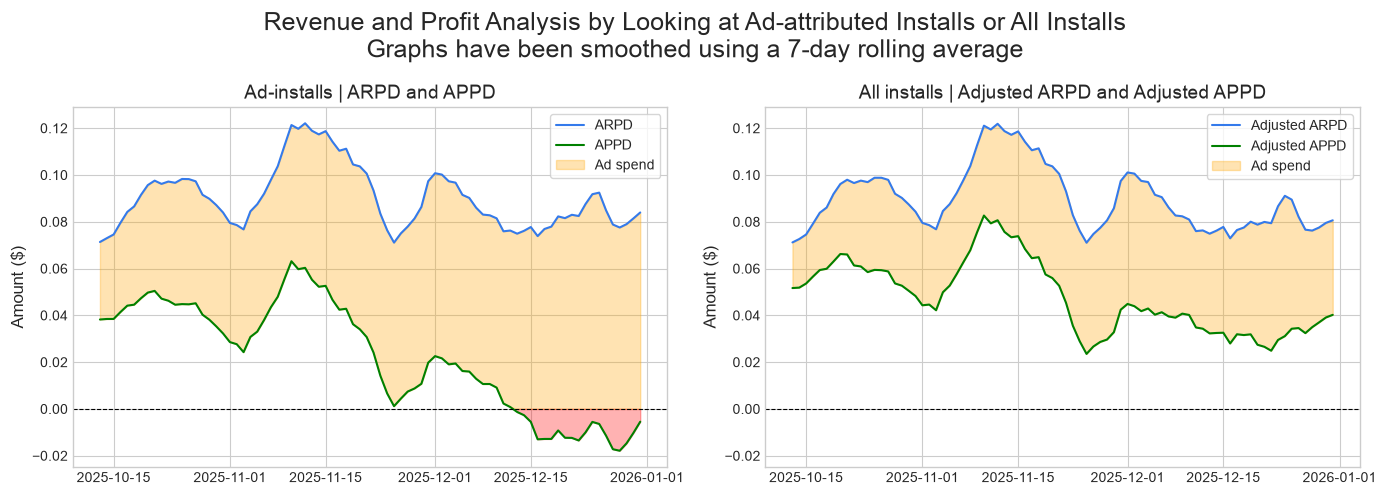

In [5]:
ads_df['estimated_total_revenue'] = ads_df['total_downloads'] * ads_df['arpd']
ads_df['total_ad_revenue'] = ads_df['arpd'] * ads_df['paid_downloads']
ads_df['estimated_total_profit'] = ads_df['estimated_total_revenue'] - ads_df['ad_spend']
ads_df['total_ad_profit'] = ads_df['appd'] * ads_df['paid_downloads']
ads_df['adjusted_cpi'] = ads_df['ad_spend'] / ads_df['total_downloads']

# ads_df[['total_revenue', 'total_ad_revenue', 'total_ad_profit', 'ad_spend']].plot()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey="row", sharex=True)

def plot_revenue_and_profit(ax, index, revenue, revenue_label, profit, profit_label, title):
    ax.plot(index, revenue, color='#347aeb',label=revenue_label)
    ax.plot(index, profit, color='green', label=profit_label)
    ax.fill_between(index, revenue, profit.clip(lower=0), alpha=0.3, color='orange', label="Ad spend")
    ax.fill_between(index, revenue.clip(upper=0), profit, where=profit < 0, alpha=0.3, color='red')
    ax.legend(frameon=True, framealpha=0.8, facecolor="white")
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Amount ($)', fontsize=12)
    ax.tick_params(labelleft=True, labelbottom=True)

arpd = ads_df['total_ad_revenue'].rolling(7).mean() / ads_df['paid_downloads'].rolling(7).mean()
appd = ads_df['total_ad_profit'].rolling(7).mean() / ads_df['paid_downloads'].rolling(7).mean()
adjusted_arpd = ads_df['estimated_total_revenue'].rolling(7).mean() / ads_df['total_downloads'].rolling(7).mean()
adjusted_appd = ads_df['estimated_total_profit'].rolling(7).mean() / ads_df['total_downloads'].rolling(7).mean()
plot_revenue_and_profit(ax1, ads_df.index, arpd, 'ARPD', appd, 'APPD', 'Ad-installs | ARPD and APPD')
plot_revenue_and_profit(ax2, ads_df.index, adjusted_arpd, 'Adjusted ARPD', adjusted_appd, 'Adjusted APPD', 'All installs | Adjusted ARPD and Adjusted APPD')

plt.suptitle('Revenue and Profit Analysis by Looking at Ad-attributed Installs or All Installs\nGraphs have been smoothed using a 7-day rolling average', fontsize=18)
plt.tight_layout()


If total downloads are an effect of the Facebook ads, then the profit per download should be placed around 0.03-0.04$, if the behaviour of the past couple weeks holds.

If, on the contrary, the downloads were independent, then we could stop the ad-campaign, which is currently bleeding money and keep the full profit from the non-paid installs.

# Actions
Now, to which actions we can take going forward:
1. Optimize ad targeting: modify the campaign so that we increase the value it returns. **Goal: higher APPD**.
2. Optimize ad spend: select the optimal amount to spend in the campaign. **Goal: higher total profit**.

## Optimize ad-targeting

If we optimize ad-targeting and have the APPD turn positive for paid-downloads, then we will have more room to explore.

#### How can we optimize the campaign?

We first need to identify if we care more about installs or profit. The ad strategy should reflect this decision. There could be several ways going forward:
* Facebook's [Advantage+](https://www.facebook.com/business/help/309994246788275?id=1858550721111595) can help us optimize volume or value.
* Seeing that a notable percentage of downloads is not being attributed by the campaign, Facebook's algorithm may not be optimizing the audience as well as it could. We can further tweak it by turning it into a [lookalike](https://www.facebook.com/business/help/164749007013531?id=401668390442328) campaign with a selection of users that are particularly relevant to us, for example: top q quantile of in-app spend, top recurring users... Even if the CPI rises, the expected ARPD should be higher


## Optimize ad-spend
Playing with ad-spend, we find ourselves under two possible scenarios regarding non-paid vs paid downloads:
#### 1. They are dependent
1. If we increase the ad-spend, assuming past performance, and that non-paid downloads stay at ~38% of all downloads, then we would be obtaining a revenue of around 0.03-0.04$ per download. If we assume that investment will have diminishing returns, there should be an optimal spend point that we can find.
2. If we decrease the ad-spend. We would see the non-paid downloads collapse, thus removing all profit.

#### 2. They are independent
1. If we increase the ad-spend, but non-paid downloads maintain their trend, then we would be eroding the profit that we had.
2. If we decrease the ad-spend. We would see the non-paid downloads keep their trend, and the negative profit of the past few weeks would be removed from the equation, thus having a higher profit.


### SImulation
To identify the potential impact of both actions, we will be **simulating** the following scenarios:
1. extra spend: increase spend by the estimated profit during the past 21 days: ~67$
    1. best case scenario: CPI remains constant.
    2. worst case scenario: CPI for new impressions (over the 90$ limit previously set) doubles (or CTR halves) 
2. decrease in spend: most extreme case, removing ad spend 
    1. best case scenario: they were independent, so we don't lose money in the campaign
    2. worst case scenario: they were dependent, so we fall back into the pre-campaign download levels

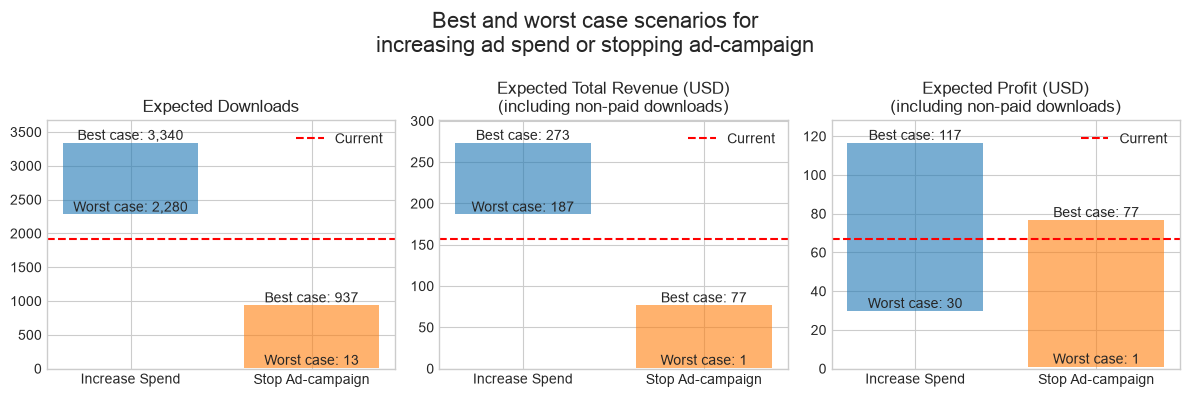

In [6]:
paid_downloads = ads_df['paid_downloads'].tail(21).mean()
non_paid_downloads = ads_df['non_paid_downloads'].tail(21).mean()
total_downloads = ads_df['total_downloads'].tail(21).mean()
total_revenue = ads_df['estimated_total_revenue'].tail(21).mean()
total_profit = ads_df['estimated_total_profit'].tail(21).mean()
arpd = ads_df['arpd'].tail(21).mean()
ad_spend = ads_df['ad_spend'].tail(21).mean()

pre_campaign_downloads = downloads_df[~downloads_df.index.isin(ads_df.index)]['downloads'].mean()


spend_increase = total_profit

spend_increase_ratio = spend_increase / ad_spend

# If we increase ad spend, in the best case scenario, where non-paid depends on paid,
# we would see the APPD stay constant while downloads increase proportionally:
increase_best_case = {
    'expected_downloads': total_downloads * (1 + spend_increase_ratio),
    'expected_revenue': total_revenue * (1 + spend_increase_ratio),
    'expected_profit': total_profit * (1 + spend_increase_ratio),
}

# In the worst case scenario, where non-paid downloads are independent of paid downloads,
# the increase in ad spend would only affect paid downloads. Let's also assume that there
# is a drastic drop in the effectiveness of paid downloads (50%).
effectiveness = 0.5
expected_downloads = non_paid_downloads + (1 + effectiveness*spend_increase_ratio)*paid_downloads
extra_downloads_ratio = expected_downloads / (non_paid_downloads + paid_downloads)
expected_revenue = extra_downloads_ratio * total_revenue
expected_profit = expected_revenue - (ad_spend + spend_increase)

increase_worst_case = {
    'expected_downloads': expected_downloads,
    'expected_revenue': expected_revenue,
    'expected_profit': expected_profit,
}

# Now for the decrease scenario, where we stop ad spend completely
expected_downloads = non_paid_downloads
expected_revenue = (expected_downloads / total_downloads) * total_revenue
expected_profit = expected_revenue

decrease_best_case = {
    'expected_downloads': expected_downloads,
    'expected_revenue': expected_revenue,
    'expected_profit': expected_profit,
}
decrease_worst_case = {
    'expected_downloads': pre_campaign_downloads,
    'expected_revenue': pre_campaign_downloads * arpd,
    'expected_profit': pre_campaign_downloads * arpd, # same as revenue, since there is no spend
}

current = {
    "downloads": total_downloads,
    "revenue": total_revenue,
    "profit": total_profit
}
scenarios = {
    "Increase Spend": {"worst": increase_worst_case, "best": increase_best_case},
    "Stop Ad-campaign": {"worst": decrease_worst_case, "best": decrease_best_case},
}
metrics = {
    "expected_downloads": "Expected Downloads",
    "expected_revenue": "Expected Total Revenue (USD)\n(including non-paid downloads)",
    "expected_profit": "Expected Profit (USD)\n(including non-paid downloads)",
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (key, label) in zip(axes, metrics.items()):
    for i, (action, s) in enumerate(scenarios.items()):
        lo, hi = s["worst"][key], s["best"][key]
        ax.bar(i, hi - lo, bottom=lo, width=0.75, color=f"C{i}", alpha=0.6)
        ax.text(i, hi, f"Best case: {hi:,.0f}", ha="center", va="bottom")
        ax.text(i, lo, f"Worst case: {lo:,.0f}", ha="center", va="bottom")

        top = scenarios['Increase Spend']['best'][key]
        ax.set_ylim(bottom=0, top=top * 1.1)

    ax.axhline(current[key.replace("expected_", "")], color="red", linestyle="--", label="Current")

    ax.set_xticks(range(len(scenarios)), scenarios.keys())
    ax.set_title(label)
    ax.margins(y=0.15)
    ax.legend(loc="upper right")

plt.suptitle('Best and worst case scenarios for\nincreasing ad spend or stopping ad-campaign', fontsize=16)
fig.tight_layout()


The displayed scenarios have been computed without taking into account how the number of downloads impacts App Store positioning, which can greatly impact the number of non-paid downloads.

### Recommendation: increase ad-spend
Once we have results of the impact, we can decide on the best amount to spend.

# Appendix
For more detailed graphs:

### Relationship between paid and non-paid downloads

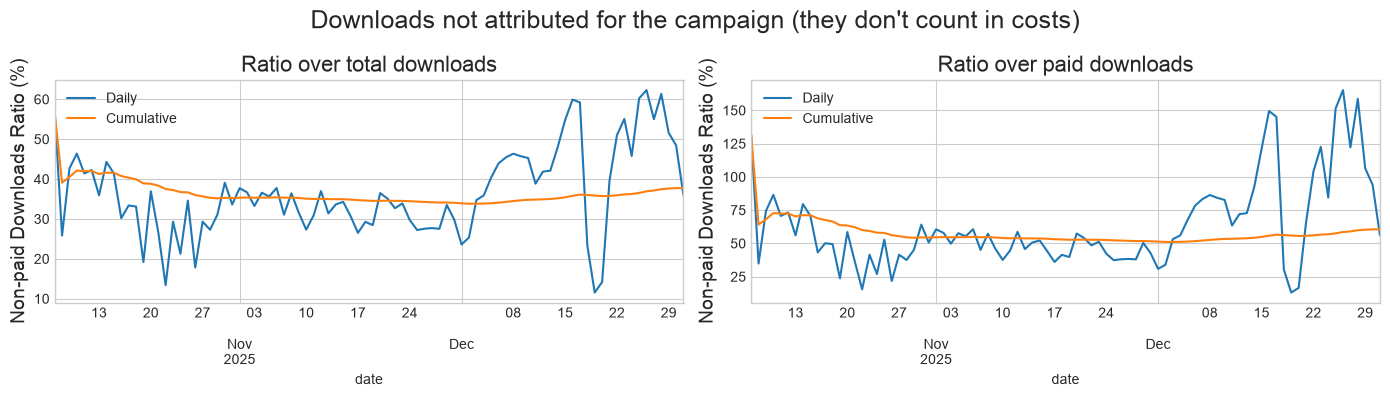

In [7]:
non_paid_downloads = ads_df['total_downloads'] - ads_df['paid_downloads']

total_downloads = ads_df['total_downloads'].cumsum()
total_paid_downloads = ads_df['paid_downloads'].cumsum()
total_non_paid_downloads = total_downloads - total_paid_downloads

# The ratio of these unpaid downloads to the paid downloads gives us the expected uplift that having this ad campaign running can generate
unpaid_ratio_over_paid = non_paid_downloads / ads_df['paid_downloads']
unpaid_ratio_smooth_over_paid = total_non_paid_downloads / total_paid_downloads

# The ratio of these unpaid downloads to the paid downloads gives us the expected uplift that having this ad campaign running can generate
unpaid_ratio_over_total = non_paid_downloads / ads_df['total_downloads']
unpaid_ratio_smooth_over_total = total_non_paid_downloads / total_downloads

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

(unpaid_ratio_over_total * 100).plot(ax=ax1, label='Daily')
(unpaid_ratio_smooth_over_total * 100).plot(ax=ax1, label='Cumulative')
ax1.legend()
ax1.set_title("Ratio over total downloads", fontsize=16)
ax1.set_ylabel("Non-paid Downloads Ratio (%)", fontsize=14)

(unpaid_ratio_over_paid * 100).plot(ax=ax2, label='Daily')
(unpaid_ratio_smooth_over_paid * 100).plot(ax=ax2, label='Cumulative')
ax2.legend()
ax2.set_title("Ratio over paid downloads", fontsize=16)
ax2.set_ylabel("Non-paid Downloads Ratio (%)", fontsize=14)

plt.suptitle("Downloads not attributed for the campaign (they don't count in costs)", fontsize=18)
plt.tight_layout()


Even though during December the ratio has increased, we can approximate the impact with the accumulated value (and revisit in the future if the trend continues upward).

#### Paid downloads get around 60% extra downloads (non-paid)
This claim would need to be verified, maybe if at any moment, we stopped paying the Facebook campaign, if the non-paid downloads continue or if they drop back to previous values near 12-13 daily downloads.

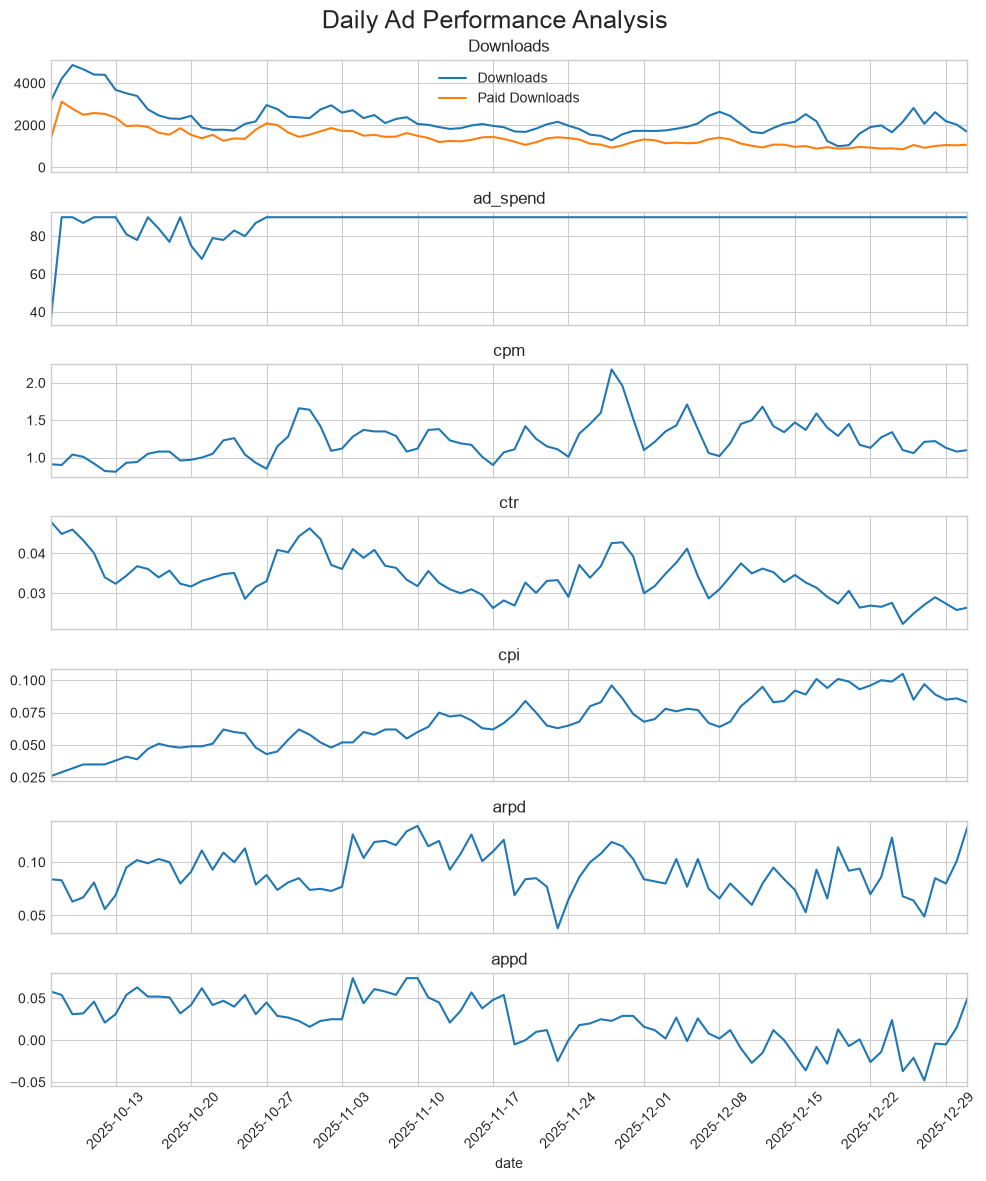

In [8]:
cols = [
    'ad_spend',
    'cpm',
    'ctr',
    # we plot this separately with the full downloads data.
    # 'paid_downloads',
    'cpi',
    'arpd',
    'appd'
]

fig, axes = plt.subplots(len(cols) + 1, 1, figsize=(10, 2*len(cols)), sharex=True)

ax = axes[0]
downloads_df['downloads'].plot(label='Downloads', ax=ax)
ads_df['paid_downloads'].plot(label='Paid Downloads', ax=ax)
ax.set_title('Downloads')
ax.legend()

for ax, col in zip(axes[1:], cols):
    ads_df[col].plot(ax=ax)
    ax.set_title(col)


all_mondays = ads_df.index[ads_df.index.weekday == 0]
all_mondays_str = all_mondays.strftime('%Y-%m-%d')
plt.xticks(all_mondays, all_mondays_str, rotation=45)

plt.suptitle('Daily Ad Performance Analysis', fontsize=18)
fig.tight_layout()


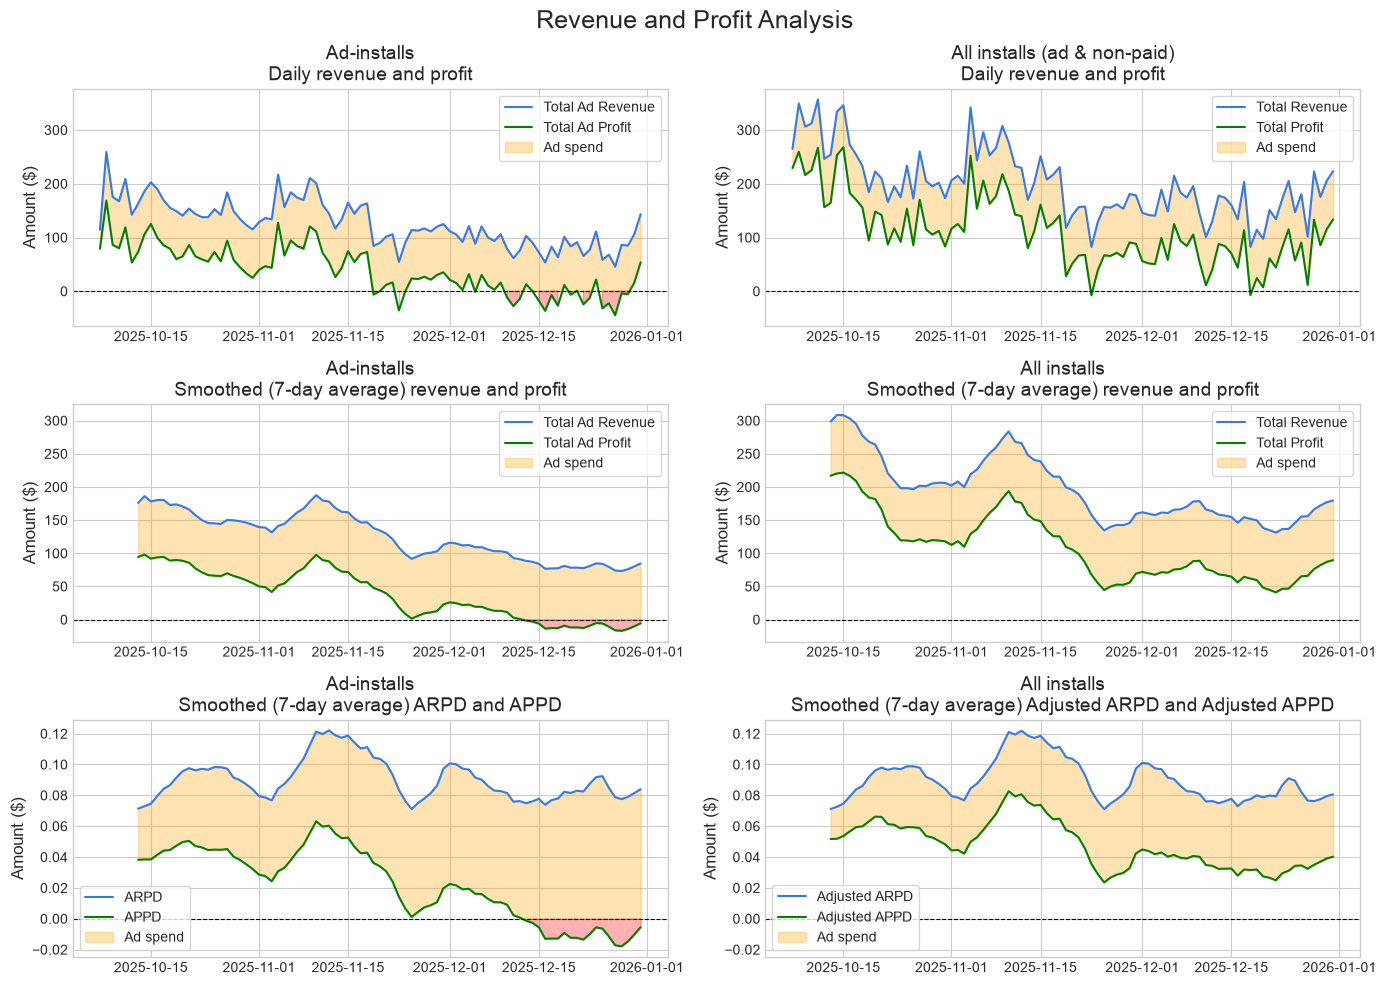

In [9]:
ads_df['estimated_total_revenue'] = ads_df['total_downloads'] * ads_df['arpd']
ads_df['total_ad_revenue'] = ads_df['arpd'] * ads_df['paid_downloads']
ads_df['estimated_total_profit'] = ads_df['estimated_total_revenue'] - ads_df['ad_spend']
ads_df['total_ad_profit'] = ads_df['appd'] * ads_df['paid_downloads']
ads_df['adjusted_cpi'] = ads_df['ad_spend'] / ads_df['total_downloads']

fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(14, 10), sharey="row", sharex=True)

def plot_revenue_and_profit(ax, index, revenue, revenue_label, profit, profit_label, title):
    ax.plot(index, revenue, color='#347aeb',label=revenue_label)
    ax.plot(index, profit, color='green', label=profit_label)
    ax.fill_between(index, revenue, profit.clip(lower=0), alpha=0.3, color='orange', label="Ad spend")
    ax.fill_between(index, revenue.clip(upper=0), profit, where=profit < 0, alpha=0.3, color='red')
    ax.legend(frameon=True, framealpha=0.8, facecolor="white")
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Amount ($)', fontsize=12)
    ax.tick_params(labelleft=True, labelbottom=True)

plot_revenue_and_profit(ax1, ads_df.index, ads_df['total_ad_revenue'], 'Total Ad Revenue', ads_df['total_ad_profit'], 'Total Ad Profit', 'Ad-installs\nDaily revenue and profit')
plot_revenue_and_profit(ax2, ads_df.index, ads_df['estimated_total_revenue'], 'Total Revenue', ads_df['estimated_total_profit'], 'Total Profit', 'All installs (ad & non-paid)\nDaily revenue and profit')

plot_revenue_and_profit(ax3, ads_df.index, ads_df['total_ad_revenue'].rolling(7).mean(), 'Total Ad Revenue', ads_df['total_ad_profit'].rolling(7).mean(), 'Total Ad Profit', 'Ad-installs\nSmoothed (7-day average) revenue and profit')
plot_revenue_and_profit(ax4, ads_df.index, ads_df['estimated_total_revenue'].rolling(7).mean(), 'Total Revenue', ads_df['estimated_total_profit'].rolling(7).mean(), 'Total Profit', 'All installs\nSmoothed (7-day average) revenue and profit')

plot_revenue_and_profit(ax5, ads_df.index, ads_df['total_ad_revenue'].rolling(7).mean() / ads_df['paid_downloads'].rolling(7).mean(), 'ARPD', ads_df['total_ad_profit'].rolling(7).mean() / ads_df['paid_downloads'].rolling(7).mean(), 'APPD', 'Ad-installs\nSmoothed (7-day average) ARPD and APPD')
plot_revenue_and_profit(ax6, ads_df.index, ads_df['estimated_total_revenue'].rolling(7).mean() / ads_df['total_downloads'].rolling(7).mean(), 'Adjusted ARPD', ads_df['estimated_total_profit'].rolling(7).mean() / ads_df['total_downloads'].rolling(7).mean(), 'Adjusted APPD', 'All installs\nSmoothed (7-day average) Adjusted ARPD and Adjusted APPD')

plt.suptitle('Revenue and Profit Analysis', fontsize=18)
plt.tight_layout()
